# 05 – Příznaky a klasifikace

**Cíl kroku:** u každé nalezené mince určit hodnotu (1, 2, 5, 10, 20, 50 Kč) a pro každou třídu vrátit skóre,
ze kterého v kroku 06 spočítáme ROC a EER.

**Data:** vlastní dataset z 14. 11. (`data/dataset/`, 1428×1071 px, iPhone 30 cm nad podložkou, viz README datasetu).

| Sada | Použití |
|---|---|
| `samostatne/` + `mix/` | trénovací |
| `dotyk/` | validační – výběr příznaků a parametrů |
| `test/` | testovací – vyhodnocení jen jednou, na konci |
| `robust/` | boční světlo – kontrola robustnosti |

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from collections import defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from coins import COIN_DIAMETERS_MM
from coins.io import load_rgb, show_images, DATASET_DIR
from coins.preprocess import preprocess
from coins.segment import segment, segment_bg, background_diff, detect_coins_bg, draw_coins, ruler_bottom
from coins.features import calibrate, diameter_px, features_table, match_to_truth
from coins.classify import NearestNeighborScores

VALUES = [1, 2, 5, 10, 20, 50]
OUT = ROOT / "results"

In [2]:
ann = pd.read_csv(DATASET_DIR / "anotace.csv", sep=";")
truth = defaultdict(list)
for r in pd.read_csv(DATASET_DIR / "anotace_mince.csv", sep=";").itertuples():
    truth[r.soubor].append((r.x, r.y, r.hodnota))

images = {f: load_rgb(DATASET_DIR / f) for f in ann.soubor}
ann.groupby("sada", sort=False).agg(snimku=("soubor", "size"), minci=("pocet", "sum"))

,snimku,minci
sada,,
samostatne,35,146
mix,21,214
dotyk,10,116
test,16,161
robust,6,46


## 1. Detekce na nové podložce

Segmentace z kroku 03 (hystereze Otsu/Triangle na kanálu V) byla laděná na černé podložce. Tady je podložka šedá
s pozvolným přechodem jasu a v záběru je červené pravítko. Navíc některé lesklé 1 a 2 Kč odrážejí tmavé okolí
a jsou tmavší než podložka.

Nový postup (`segment_bg`):
1. **Odečtení pozadí:** pozadí = mediánový filtr s jádrem větším než mince (počítaný na 4× zmenšeném snímku),
   prahujeme |V − pozadí|. Najde mince světlejší i tmavší než podložka a nevadí mu změna jasu přes snímek.
2. **Pravítko:** řádky, kde je víc než 30 % červených pixelů; vše nad ním se ignoruje.
3. **Watershed** z kroku 04 pro dotýkající se mince.
4. **Kruhovitost na konvexním obalu:** tmavý lesklý kus mince někdy splyne s podložkou a kontura je „ukousnutá“.

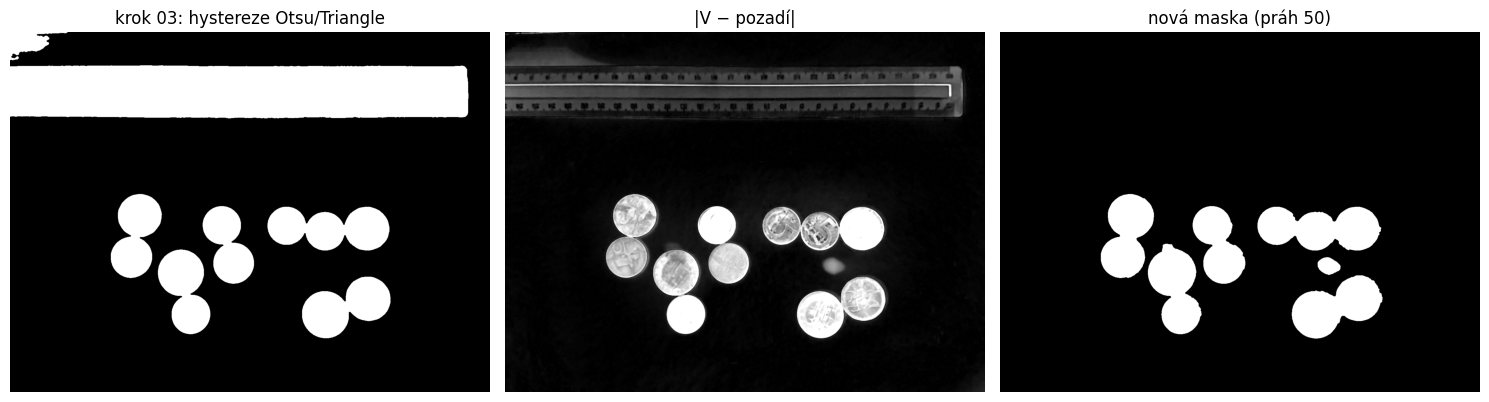

In [3]:
name = "dotyk/dotyk_03.jpg"
img = images[name]
old = segment(preprocess(img))
diff = background_diff(preprocess(img))
new = segment_bg(img)
show_images([old, diff, new], ["krok 03: hystereze Otsu/Triangle", "|V − pozadí|", "nová maska (práh 50)"], cols=3, size=5)

Úspěšnost detekce měříme proti ruční anotaci poloh (`anotace_mince.csv`): detekce je správná, když je její střed
do 25 px od anotované mince. Práh rozdílu jsme vybírali **jen na trénovací a validační sadě**.

In [4]:
def detection_stats(detect, names):
    rows = []
    for f in names:
        coins = detect(images[f])
        labels, missed = match_to_truth(coins, truth[f])
        tp = sum(v is not None for v in labels)
        rows.append({"sada": f.split("/")[0], "TP": tp, "FN": missed, "FP": len(coins) - tp})
    return pd.DataFrame(rows).groupby("sada", sort=False).sum()

dev = ann.soubor[ann.sada.isin(["samostatne", "mix", "dotyk"])]
rows = []
for thr in [30, 40, 50, 60, 70]:
    s = detection_stats(lambda im: detect_coins_bg(im, thr), dev).sum()
    rows.append({"práh": thr, **s.to_dict()})
pd.DataFrame(rows)

,práh,TP,FN,FP
0,30,476,0,1
1,40,476,0,0
2,50,476,0,0
3,60,475,1,0
4,70,475,1,0


Prahy 40 a 50 najdou všech 476 mincí bez falešné detekce, zvolili jsme **50** (dál od šumu podložky).
Pro srovnání stará segmentace z kroku 03:

In [5]:
def detect_old(im):
    from coins.segment import split_touching, find_coins
    m = segment(preprocess(im))
    return find_coins(m, split_touching(im, m), min_area=2000)

pd.concat({"krok 03": detection_stats(detect_old, dev), "odečtení pozadí": detection_stats(detect_coins_bg, dev)}, axis=1)

krok 03        odečtení pozadí      
                TP  FN FP              TP FN FP
sada                                           
samostatne     132  14  0             146  0  0
mix            214   0  0             214  0  0
dotyk          114   2  0             116  0  0

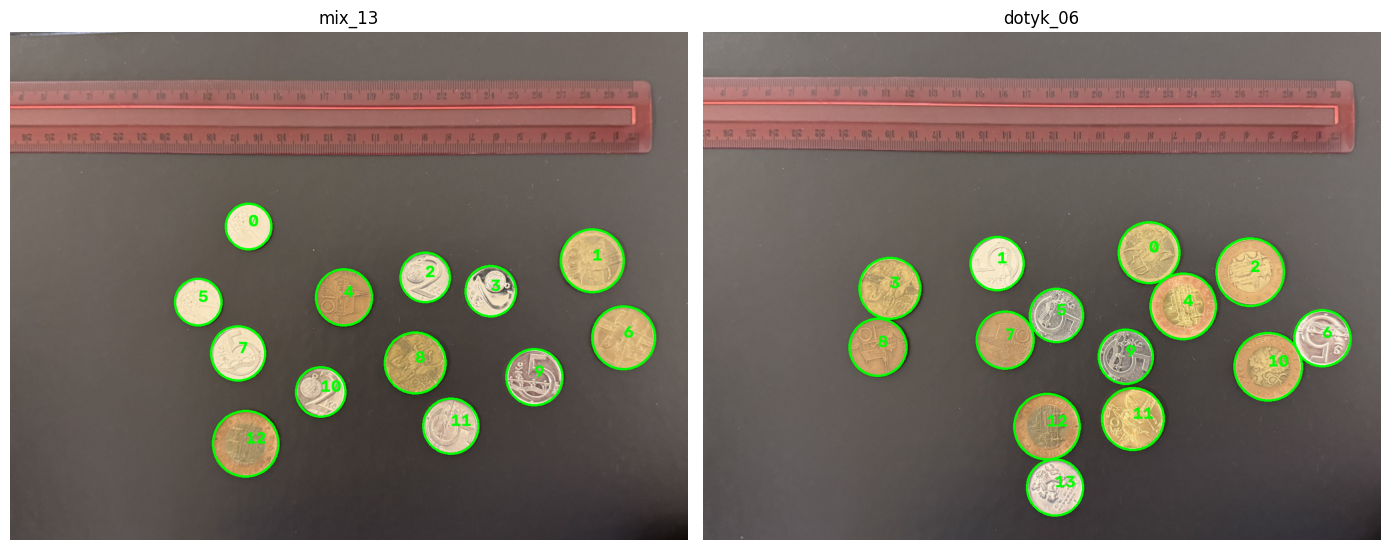

In [6]:
detections = {f: detect_coins_bg(images[f]) for f in ann.soubor}
show_images([draw_coins(images[f], detections[f]) for f in ["mix/mix_13.jpg", "dotyk/dotyk_06.jpg"]],
            ["mix_13", "dotyk_06"], cols=2, size=7)

## 2. Kalibrace px → mm

Telefon byl celou dobu ve stejné výšce a všechny snímky mají stejné rozlišení, takže stačí jedno měřítko.
Pravítko je v záběru oříznuté (levý konec chybí), proto kalibrujeme podle **mincí známého průměru** (údaje ČNB)
na trénovacích snímcích `samostatne/`: nejmenší čtverce pro d_px ≈ k · d_mm.

**Průměr mince** měříme jako menší osu elipsy proložené konturou. Opsaná kružnice (`minEnclosingCircle`) je citlivá
na každý výběžek – stín nebo kousek sousední mince po watershedu – a u dotýkajících se mincí vycházela o 0,5 mm větší
s rozptylem 0,9 mm. Menší osa elipsy má rozptyl kolem 0,25 mm, přičemž sousední hodnoty se liší o 1,5 mm.

In [7]:
sam = ann.soubor[ann.sada == "samostatne"]
d_px, vals = [], []
for f in sam:
    labels, _ = match_to_truth(detections[f], truth[f])
    d_px += [diameter_px(c) for c in detections[f]]
    vals += labels
PX_PER_MM = calibrate(d_px, vals)

check = pd.DataFrame({"hodnota": vals, "prumer_mm": np.array(d_px) / PX_PER_MM})
check = check.groupby("hodnota").prumer_mm.agg(["mean", "std", "size"]).round(2)
check["ČNB"] = [COIN_DIAMETERS_MM[v] for v in check.index]
print(f"měřítko: {PX_PER_MM:.3f} px/mm (pravítko 30 cm by mělo {300 * PX_PER_MM:.0f} px, snímek má 1428 px)")
check

měřítko: 4.876 px/mm (pravítko 30 cm by mělo 1463 px, snímek má 1428 px)


,mean,std,size,ČNB
hodnota,,,,
1,20.00,0.16,18,20.0
2,21.37,0.12,30,21.5
5,23.08,0.20,30,23.0
10,24.58,0.17,24,24.5
20,25.98,0.15,24,26.0
50,27.48,0.22,20,27.5


## 3. Příznaky

Pro každou mince (`coin_features`):
- **průměr v mm**,
- **sytost S a odstín H uprostřed** (kruh do 0,5 r) – stříbrné 1/2/5 Kč mají S ≈ 40, měděná 10 Kč a mosazné 20/50 Kč S ≈ 110,
- **sytost a odstín na okraji** (mezikruží 0,72–0,92 r) – u 50 Kč je okraj z jiného kovu než střed.

Kruhovitost (2 Kč je 11hranná, 20 Kč 13hranná) jsme zkoušeli, ale při rozlišení ~120 px na minci je rozdíl proti kruhu
pod rozlišovací schopností (0,99 vs 1,00), proto ji nepoužíváme.

In [8]:
T = features_table(images, detections, PX_PER_MM, truth)
T["sada"] = T.soubor.str.split("/").str[0]
known = T[T.hodnota.notna()].copy()
known["hodnota"] = known.hodnota.astype(int)
train = known[known.sada.isin(["samostatne", "mix"])]
val = known[known.sada == "dotyk"]
test = known[known.sada == "test"]
robust = known[known.sada == "robust"]

train.groupby("hodnota")[["prumer_mm", "S_stred", "H_stred", "S_okraj", "H_okraj"]].agg(["mean", "std"]).round(1)

prumer_mm      S_stred       H_stred      S_okraj       H_okraj     
             mean  std    mean   std    mean  std    mean   std    mean  std
hodnota                                                                     
1            19.9  0.1    44.5  11.2    19.2  2.4    42.9  10.6    19.2  2.2
2            21.3  0.2    37.3  10.8    19.2  5.3    37.4  10.9    19.2  4.9
5            23.1  0.3    47.8   8.8    17.2  3.8    47.6   8.7    17.0  3.7
10           24.5  0.2   113.4   8.3    16.2  0.5   112.6   8.8    16.2  0.6
20           26.0  0.2   107.7   8.5    20.4  1.3   109.4   8.8    20.0  1.1
50           27.6  0.3   109.2   9.4    20.5  1.2   122.0   5.9    15.4  1.1

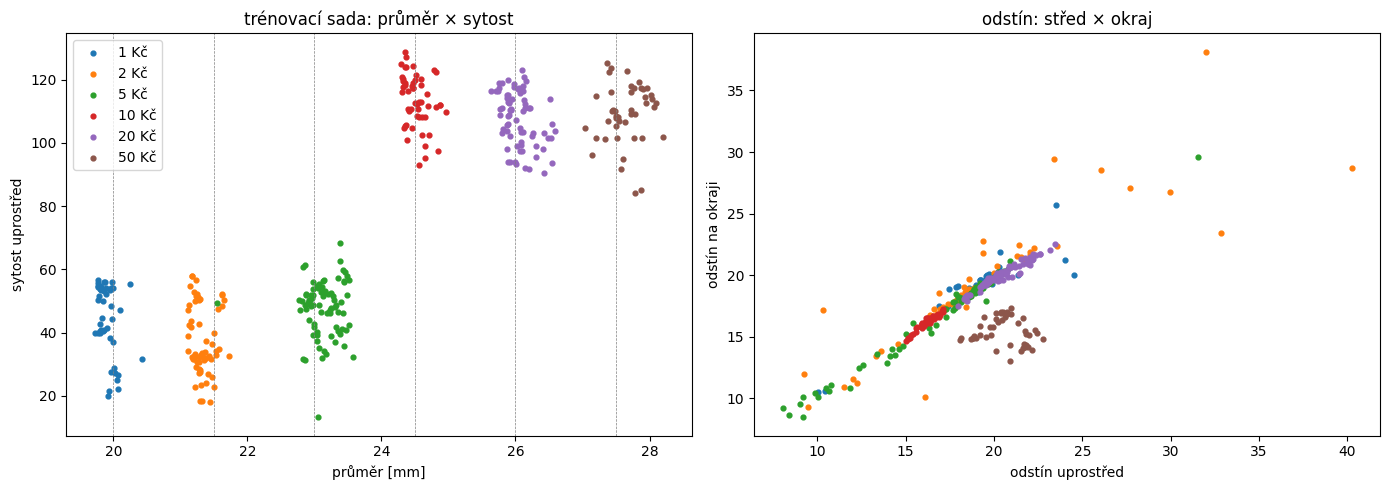

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for v in VALUES:
    s = train[train.hodnota == v]
    axes[0].scatter(s.prumer_mm, s.S_stred, s=12, label=f"{v} Kč")
    axes[1].scatter(s.H_stred, s.H_okraj, s=12, label=f"{v} Kč")
for x in COIN_DIAMETERS_MM.values():
    axes[0].axvline(x, color="gray", lw=0.5, ls="--")
axes[0].set(xlabel="průměr [mm]", ylabel="sytost uprostřed", title="trénovací sada: průměr × sytost")
axes[1].set(xlabel="odstín uprostřed", ylabel="odstín na okraji", title="odstín: střed × okraj")
axes[0].legend(); plt.tight_layout(); plt.show()

Průměr sám o sobě oddělí všech šest hodnot (svislé čáry = průměry podle ČNB). Sytost odděluje stříbrné mince
od barevných. Odstín pomáhá jen u barevných mincí (50 Kč má okraj „červenější“ než střed), u stříbrných je to šum.

## 4. Klasifikátor podle nejbližšího souseda

`NearestNeighborScores`: příznaky se standardizují podle trénovací sady a pro každou třídu se spočítá vzdálenost
k nejbližším trénovacím vzorkům té třídy (průměr z k nejbližších). Předpověď = třída s nejmenší vzdáleností,
**skóre třídy = −vzdálenost**, které v kroku 06 použijeme pro ROC a EER.

Kombinaci příznaků a k vybíráme podle úspěšnosti na validační sadě (`dotyk/`).

In [10]:
FEATURE_SETS = {
    "průměr": ["prumer_mm"],
    "průměr + sytost": ["prumer_mm", "S_stred"],
    "průměr + sytost + odstín okraje": ["prumer_mm", "S_stred", "S_okraj", "H_okraj"],
    "vše": ["prumer_mm", "S_stred", "H_stred", "S_okraj", "H_okraj"],
}
rows = []
for name, feats in FEATURE_SETS.items():
    row = {"příznaky": name}
    for k in [1, 3, 5]:
        model = NearestNeighborScores(k).fit(train[feats], train.hodnota)
        row[f"k={k}"] = (model.predict(val[feats]) == val.hodnota).mean()
    rows.append(row)
pd.DataFrame(rows).set_index("příznaky").style.format("{:.1%}")

,k=1,k=3,k=5
příznaky,,,
průměr,99.1%,99.1%,99.1%
průměr + sytost,100.0%,100.0%,100.0%
průměr + sytost + odstín okraje,98.3%,96.6%,96.6%
vše,96.6%,94.8%,95.7%


Nejlépe vychází **průměr + sytost uprostřed** (100 % pro všechna k). Přidání odstínu zhoršuje výsledek – u stříbrných
mincí je odstín náhodný a ve standardizovaném prostoru přidává šum. Volíme **k = 3**: výsledek je stejný jako pro k = 1,
ale skóre (průměr ze tří vzdáleností) je méně citlivé na jeden odlehlý trénovací vzorek.

In [11]:
FEATURES = FEATURE_SETS["průměr + sytost"]
K = 3

def confusion(y_true, y_pred):
    return pd.crosstab(pd.Series(y_true, name="skutečnost"), pd.Series(y_pred, name="předpověď")).reindex(
        index=VALUES, columns=VALUES, fill_value=0)

model = NearestNeighborScores(K).fit(train[FEATURES], train.hodnota)
confusion(val.hodnota.values, model.predict(val[FEATURES]))

předpověď,1,2,5,10,20,50
skutečnost,,,,,,
1,8,0,0,0,0,0
2,0,4,0,0,0,0
5,0,0,38,0,0,0
10,0,0,0,22,0,0
20,0,0,0,0,24,0
50,0,0,0,0,0,20


## 5. Vyhodnocení na testovací sadě

Model natrénujeme znovu na trénovací + validační sadě a jednou vyhodnotíme na `test/`. Sledujeme:
- **úspěšnost po mincích** (jen správně detekované mince) a matici záměn,
- **přesný součet na snímku** – zahrnuje i chyby detekce (chybějící nebo falešná mince), tedy kontrolu celého systému
  (akceptační kritérium: ≥ 90 % snímků).

In [12]:
final = NearestNeighborScores(K).fit(pd.concat([train, val])[FEATURES], pd.concat([train, val]).hodnota)
T["predikce"] = final.predict(T[FEATURES])

def image_sums(sada):
    rows = []
    for f in ann.soubor[ann.sada == sada]:
        pred = T[T.soubor == f].predikce.sum()
        true = ann.loc[ann.soubor == f, "soucet"].item()
        labels, missed = match_to_truth(detections[f], truth[f])
        rows.append({"soubor": f, "součet": true, "systém": int(pred), "správně": pred == true,
                     "chybí": missed, "navíc": sum(v is None for v in labels)})
    return pd.DataFrame(rows)

test_pred = final.predict(test[FEATURES])
sums_test = image_sums("test")
print(f"test – úspěšnost po mincích: {(test_pred == test.hodnota).mean():.1%} ({(test_pred == test.hodnota).sum()}/{len(test)})")
print(f"test – přesný součet: {sums_test['správně'].mean():.1%} snímků ({sums_test['správně'].sum()}/{len(sums_test)})")
confusion(test.hodnota.values, test_pred)

test – úspěšnost po mincích: 99.4% (159/160)
test – přesný součet: 93.8% snímků (15/16)


předpověď,1,2,5,10,20,50
skutečnost,,,,,,
1,9,0,0,0,0,0
2,1,13,0,0,0,0
5,0,0,49,0,0,0
10,0,0,0,31,0,0
20,0,0,0,0,34,0
50,0,0,0,0,0,23


In [13]:
sums_test[~sums_test["správně"]]

,soubor,součet,systém,správně,chybí,navíc
13,test/test_14.jpg,132,176,False,1,1


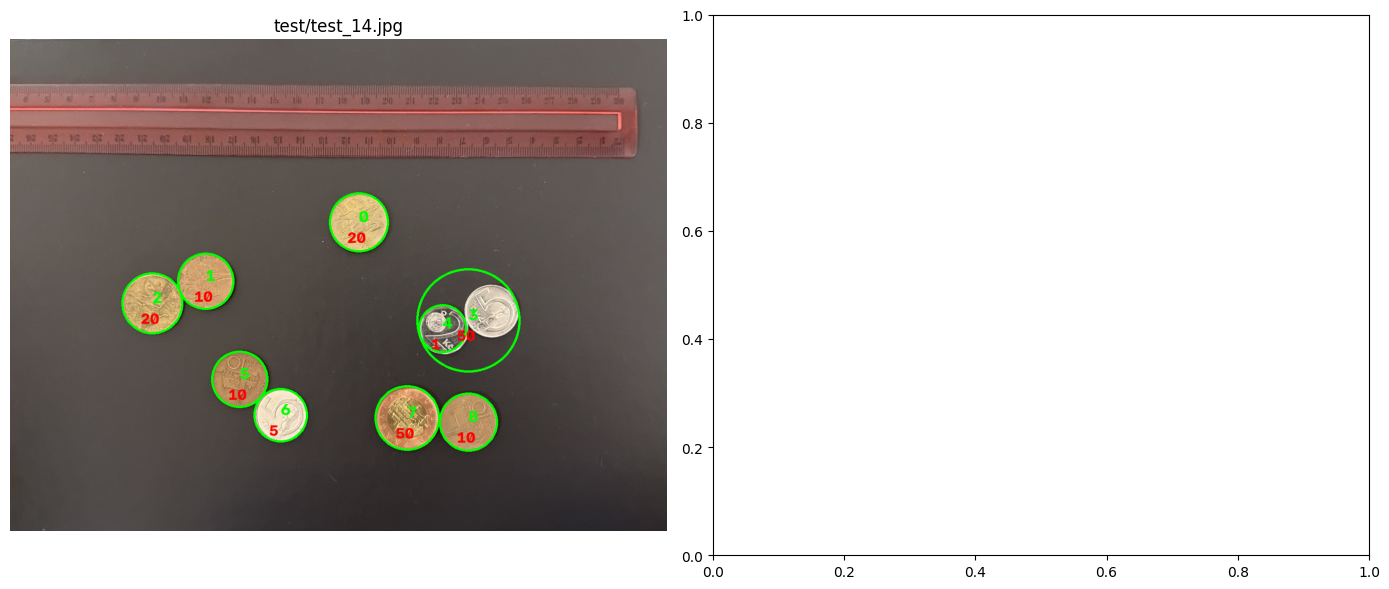

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, f in zip(axes, sums_test[~sums_test["správně"]].soubor.tolist()[:2] or ["test/test_01.jpg"]):
    vis = draw_coins(images[f], detections[f])
    for row in T[T.soubor == f].itertuples():
        cv2.putText(vis, str(row.predikce), (int(row.x) - 25, int(row.y) + 45), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (255, 0, 0), 3)
    ax.imshow(vis); ax.set_title(f); ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Robustnost: boční světlo

`robust/` jsou snímky s baterkou zboku (silný přechod jasu a barevný nádech). Model ani prahy jsme na nich neladili.

In [15]:
rob_pred = final.predict(robust[FEATURES])
sums_rob = image_sums("robust")
print(f"robust – detekce: {sums_rob['chybí'].sum()} chybějících, {sums_rob['navíc'].sum()} falešných z {ann[ann.sada == 'robust'].pocet.sum()} mincí")
print(f"robust – úspěšnost po mincích: {(rob_pred == robust.hodnota).mean():.1%}")
print(f"robust – přesný součet: {sums_rob['správně'].mean():.1%} snímků")
confusion(robust.hodnota.values, rob_pred)

robust – detekce: 7 chybějících, 0 falešných z 46 mincí
robust – úspěšnost po mincích: 74.4%
robust – přesný součet: 16.7% snímků


předpověď,1,2,5,10,20,50
skutečnost,,,,,,
1,2,0,0,0,0,0
2,0,2,0,2,0,0
5,0,1,10,2,0,0
10,0,0,0,6,0,0
20,1,0,0,2,6,0
50,1,0,0,1,0,3


In [16]:
cmp = robust.assign(predikce=rob_pred)[["soubor", "hodnota", "predikce", "prumer_mm", "S_stred"]]
cmp[cmp.hodnota != cmp.predikce].round(1)

,soubor,hodnota,predikce,prumer_mm,S_stred
637,robust/robust_bocni_svetlo_1.jpg,2,10,21.1,116.4
640,robust/robust_bocni_svetlo_1.jpg,20,10,22.1,97.7
651,robust/robust_bocni_svetlo_2.jpg,5,2,21.3,18.3
658,robust/robust_bocni_svetlo_4.jpg,2,10,20.9,133.5
662,robust/robust_bocni_svetlo_4.jpg,20,10,24.5,107.2
663,robust/robust_bocni_svetlo_4.jpg,50,1,16.5,56.5
667,robust/robust_bocni_svetlo_5.jpg,50,10,24.7,100.0
669,robust/robust_bocni_svetlo_5.jpg,5,10,23.8,85.5
670,robust/robust_bocni_svetlo_6.jpg,20,1,20.6,72.1
675,robust/robust_bocni_svetlo_6.jpg,5,10,23.7,87.5


## 7. Uložení výsledků

- `results/05_priznaky.csv` – příznaky, anotace a předpověď každé detekované mince,
- `results/05_skore_test.csv` – skóre všech tříd pro mince testovací sady (vstup pro ROC a EER v kroku 06),
- `results/05_soucty.csv` – součty po snímcích pro test a robust.

In [17]:
T.round(3).to_csv(OUT / "05_priznaky.csv", index=False)

scores = pd.DataFrame(final.decision_function(test[FEATURES]), columns=[f"skore_{v}" for v in final.classes_])
pd.concat([test[["soubor", "id", "hodnota"]].reset_index(drop=True), scores.round(4)], axis=1).to_csv(
    OUT / "05_skore_test.csv", index=False)

pd.concat([sums_test.assign(sada="test"), sums_rob.assign(sada="robust")]).to_csv(OUT / "05_soucty.csv", index=False)

## Závěr

- **Detekce:** odečtení pozadí + maska pravítka + kruhovitost na konvexním obalu najde na trénovacích a validačních
  snímcích všech 476 mincí bez falešné detekce (stará segmentace z kroku 03: 460/476). Na testu 160/161, jedna
  dvojice dotýkajících se mincí (`test_14`) se slila v jednu detekci.
- **Kalibrace:** 4,876 px/mm podle mincí známého průměru; naměřené průměry sedí s ČNB na ±0,13 mm, rozptyl 0,1–0,2 mm.
- **Příznaky:** stačí **průměr v mm + sytost uprostřed**. Odstín na validaci výsledek zhoršil (u stříbrných mincí je šum),
  kruhovitost mnohoúhelníků (2 a 20 Kč) je při tomto rozlišení neměřitelná.
- **Test:** 99,4 % mincí správně (159/160), jediná záměna 2 → 1 Kč; **přesný součet na 15 z 16 snímků (93,8 %)**,
  tedy nad akceptačním kritériem 90 %. Chybný snímek je chyba detekce (slitá dvojice), ne klasifikace.
- **Boční světlo (`robust/`):** výrazně hůř – 7 ze 46 mincí nenalezeno, 74 % správně, přesný součet jen na 1 ze 6 snímků.
  Světlo baterky mění sytost (stříbrné mince vypadají „měděně“) a stíny posouvají okraj masky, takže selhávají oba příznaky.
  Řízená scéna z zadání tento případ nevyžaduje, ale je to hlavní slabina; v dalších krocích pomůže CNN a případně
  normalizace barvy podle podložky.

**Další krok (06):** ze skóre v `results/05_skore_test.csv` spočítat ROC a EER pro každou třídu a porovnat s MLP.
